In [ ]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy import stats
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import pandas as pd

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
import matplotlib.patches as mpatches
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            # if i > trend_select and i < (len_amp - trend_select - min_len):
            #     continue
            # # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            # if (j - i - min_len) > trend_select:
            #     continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]


    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    else:
        return diff, sign, p_diff

In [3]:
# 读取Boreal数据
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-Trendy/'
files = os.listdir(folder)
model_dict = {}
exp_list = ['control', 'CFE', 'CLIM', 'LULCC']

for file in files:
    model = file.split('.')[0]
    if model == 'VISIT':
        continue
    if model == 'CLM5':
        model = 'CLM5.0'
    with xr.open_dataset(os.path.join(folder, file)) as ds:
        amp_region_temp = ds['amp_cum_region'].values
        amp_region = np.zeros_like(amp_region_temp)
        amp_region[0] = amp_region_temp[-1]                      # Control
        amp_region[1] = amp_region_temp[1]                       # CFE
        amp_region[2] = amp_region_temp[2] - amp_region_temp[1]  # Climate
        amp_region[3] = amp_region_temp[3] - amp_region_temp[2]  # LULCC
        model_dict[model] = {
            'amp_boreal': amp_region,
            'time': ds['time'].values,
        }

In [4]:
# 读取Temperate land累积碳AMP
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-Temperate-land-amp-cum-region/'
exp_origin_list = ['S0', 'S1', 'S2', 'S3']

for model in model_dict.keys():
    amp_cum = []
    if model == 'Trendy':
        continue
    for exp in exp_origin_list:
        file = os.listdir(os.path.join(folder, exp, model))[0]
        file_path = os.path.join(folder, exp, model, file)
        ds = xr.open_dataset(file_path)
        amp_cum.append(ds['amp_cum'].values[-1])
    amp_cum = np.array(amp_cum)
    amp_cum_temp = np.zeros_like(amp_cum)
    amp_cum_temp[0] = amp_cum[-1]
    amp_cum_temp[1] = amp_cum[1]
    amp_cum_temp[2] = amp_cum[2] - amp_cum[1]
    amp_cum_temp[3] = amp_cum[3] - amp_cum[2] 
    # 截取1980-2021
    model_dict[model]['amp_temp'] = amp_cum_temp

## 计算Trendy集合
amp_cum_trendy = []
amp_wind_trendy = []
for model in model_dict.keys():
    if model == 'Trendy':
        continue
    amp_cum_trendy.append(model_dict[model]['amp_temp'])

amp_cum_trendy = np.array(amp_cum_trendy).mean(axis=0)
model_dict['Trendy']['amp_temp'] = amp_cum_trendy

In [5]:
# 计算trend diff
min_line = 20
trend_select = 7
count_diff = np.sum(np.arange(1, trend_select + 1))

for model, info in model_dict.items():
    time = info['time']
    amp_boreal = info['amp_boreal']
    amp_temp = info['amp_temp']
    amp = np.array([amp_boreal, amp_temp])

    diff = np.full((2, len(exp_list), count_diff), np.nan) # 2是boreal和temperate，count_diff是趋势差的数量
    sign = np.full((2, len(exp_list)), np.nan)
    p_value = np.full((2, len(exp_list)), np.nan)

    for i in range(2):
        for j in range(len(exp_list)):
            diff[i, j, :], sign[i, j], p_value[i, j] = cal_trend_diff(
                amp[i, j], time, min_line, trend_select
            )
    
    model_dict[model]['diff'] = diff
    model_dict[model]['sign'] = sign
    model_dict[model]['p_value'] = p_value

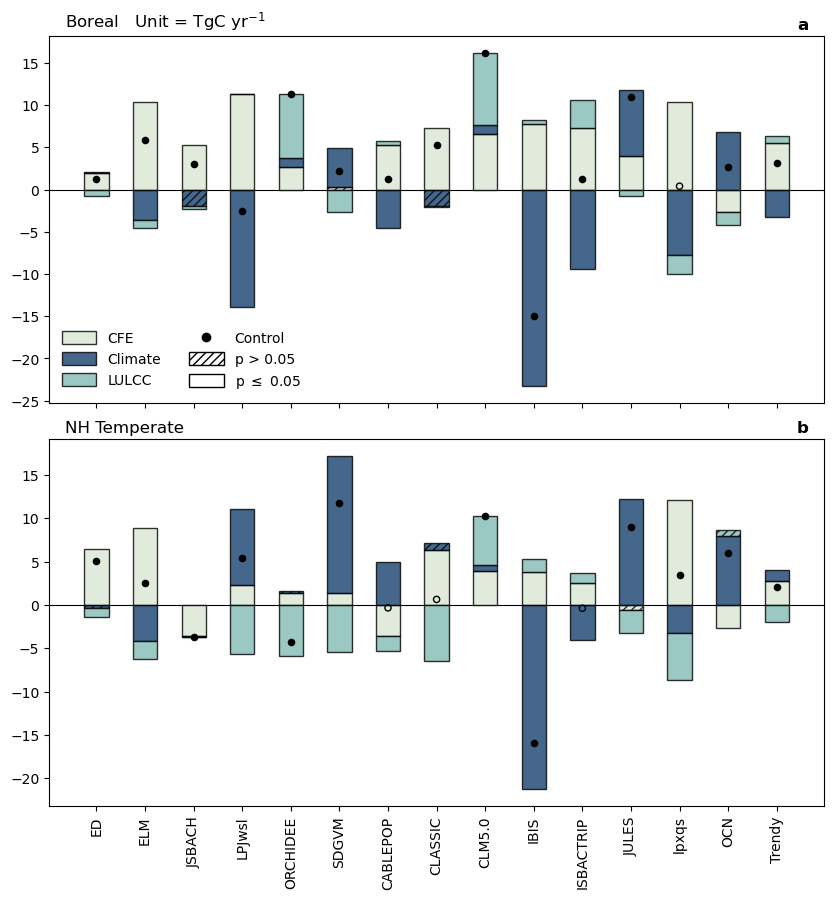

In [6]:
fig = plt.figure(figsize=(10, 10))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.1)
axs = np.empty(2, dtype=object)
for i in range(2):
    axs[i] = fig.add_subplot(gs[i])

colors = ['#dae6d3', '#16416e', '#83bbb4']
model_keys = list(model_dict.keys())
n_models = len(model_keys)
n_exp = len(exp_list)

for n_r in range(2):
    ax = axs[n_r]

    bar_mean = np.zeros((n_exp, n_models))
    bar_std = np.zeros((n_exp, n_models))
    p_vals = np.ones((n_exp, n_models))
    sig_vals = np.ones((n_exp, n_models))

    for n_m, (model, info) in enumerate(model_dict.items()):
        diff = info['diff'][n_r]
        sign = info['sign'][n_r]
        p_value = info['p_value'][n_r]

        bar_mean[:, n_m] = diff.mean(axis=-1)
        bar_std[:, n_m] = diff.std(axis=-1)
        p_vals[:, n_m] = p_value
        sig_vals[:, n_m] = sign
    
    x_data = np.arange(n_models)
    bottom_pos = np.zeros(n_models)
    bottom_neg = np.zeros(n_models)

    for n_e, exp in enumerate(exp_list[1:]):
        y_data = bar_mean[n_e+1]
        y_err = bar_std[n_e+1]
        p_data = p_vals[n_e+1]
        y_data = y_data * 1000 # 转换为 TgC yr^-1
        
        # 根据 y 值的正负选择对应的底线
        bottom = np.where(y_data > 0, bottom_pos, bottom_neg)
        
        bars = ax.bar(x_data, y_data, bottom=bottom, label=exp, 
                    color=colors[n_e], width=0.5,
                    edgecolor='black', linewidth=1, alpha=0.8)

        for idx, rect in enumerate(bars):
            if p_data[idx] > 0.1:
                rect.set_hatch('////')

        # 更新底线
        bottom_pos += np.maximum(y_data, 0)
        bottom_neg += np.minimum(y_data, 0)
    ax.axhline(0, color='black', linewidth=0.8, zorder=0)
    # 提取 control 组 (index 0) 的数据和 p 值
    y_control = bar_mean[0] * 1000
    p_control = p_vals[0]
    sig_mask = p_control <= 0.1
    nosig_mask = p_control > 0.1
    ax.scatter(x_data[sig_mask], y_control[sig_mask], color='black', marker='o', s=20, zorder=5)
    ax.scatter(x_data[nosig_mask], y_control[nosig_mask], facecolors='none', edgecolors='black', marker='o', s=20, zorder=5)

custom_lines = [
    mpatches.Patch(facecolor=colors[i], edgecolor='black', linewidth=1, alpha=0.8) 
    for i in range(len(exp_list)-1)
]
custom_lines.append(Line2D([0], [0], marker='o', color='black', markerfacecolor='black', markersize=6, lw=0, label='Control'))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', hatch='////', linewidth=1))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', linewidth=1))
labels_legend = ['CFE', 'Climate', 'LULCC', 'Control', 'p > 0.05', 'p $\leq$ 0.05']
axs[0].legend(custom_lines, labels_legend, 
          loc='lower left', frameon=False, fontsize=10,
          handlelength=2.5, handleheight=1., ncols=2)

letters = ['a', 'b']
titles = ['Boreal   Unit = TgC yr$^{-1}$', 'NH Temperate']
for i in range(2):
    ax = axs[i]
    ax.set_xticks(x_data)
    if i == 0:
        ax.set_xticklabels([])
    else:
        ax.set_xticklabels(model_keys, rotation=90, ha='center', fontsize=10)
    ax.text(0.98, 1.01, letters[i], transform=ax.transAxes, ha='right', va='bottom', 
            fontsize=12, fontweight='bold')
    ax.text(0.02, 1.01, titles[i], transform=ax.transAxes, ha='left', va='bottom', 
            fontsize=12)
    
fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-4-GC-CCA-diff-bar.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)

In [7]:
# Leave-one-model-out ensembles; original model_dict and figures are unchanged.

# 参数设置
loo_min_line = int(globals().get('min_line', 20))
loo_trend_select = int(globals().get('trend_select', 7))
loo_models = [name for name in model_dict if name != 'Trendy']
loo_regions = ['Boreal', 'NH Temperate']
loo_fields = ['amp_boreal', 'amp_temp']
loo_experiments = list(exp_list)
loo_years = np.asarray(model_dict[loo_models[0]]['time'], dtype=float)

# 检查输入数据
assert len(loo_models) >= 3 and 'IBIS' in loo_models
assert loo_experiments == ['control', 'CFE', 'CLIM', 'LULCC']
assert np.all(np.isfinite(loo_years)) and np.all(np.diff(loo_years) == 1)

# 整理输入数据
loo_inputs = []
for name in loo_models:
    np.testing.assert_array_equal(model_dict[name]['time'], loo_years)
    values = np.stack([model_dict[name][field] for field in loo_fields])
    assert values.shape == (2, 4, len(loo_years))
    assert np.all(np.isfinite(values)), f'{name}: non-finite CCA values'
    loo_inputs.append(values)
loo_inputs = np.stack(loo_inputs)

# 定义趋势差异权重计算函数
def loo_trend_difference_weights(n_years, minimum_length, selected_size):
    matrix_size = n_years - minimum_length
    if matrix_size < 2 * selected_size:
        raise ValueError('Earlier and recent submatrices overlap or are too short')
    recent_offset = matrix_size - selected_size
    weights, windows = [], []
    for row in range(selected_size):
        for column in range(row, selected_size):
            early_start, early_end = row, minimum_length + column
            recent_start, recent_end = recent_offset + row, recent_offset + minimum_length + column
            n = early_end - early_start
            centered = np.arange(1, n + 1, dtype=float)
            centered -= centered.mean()
            slope_weights = centered / np.sum(centered**2)
            weight = np.zeros(n_years)
            weight[early_start:early_end] -= slope_weights
            weight[recent_start:recent_end] += slope_weights
            weights.append(weight)
            windows.append((early_start, early_end, recent_start, recent_end))
    return np.array(weights), windows

# 计算权重和窗口
loo_weights, loo_windows = loo_trend_difference_weights(len(loo_years), loo_min_line, loo_trend_select)
assert len(loo_windows) == loo_trend_select * (loo_trend_select + 1) // 2
np.testing.assert_allclose(loo_weights.sum(axis=1), 0, atol=1e-14)

# 计算 LOO 结果
loo_scenario_names = ['All models'] + [f'Without {name}' for name in loo_models]
loo_ensemble_dict = {}
for scenario, excluded in zip(loo_scenario_names, [None] + loo_models):
    keep = np.array([name != excluded for name in loo_models])
    ensemble_amp = loo_inputs[keep].mean(axis=0)
    difference = ensemble_amp @ loo_weights.T
    loo_ensemble_dict[scenario] = {
        'excluded_model': excluded,
        'included_models': [name for name in loo_models if name != excluded],
        'n_models': int(keep.sum()),
        'time': loo_years.copy(),
        'amp_boreal': ensemble_amp[0],
        'amp_temp': ensemble_amp[1],
        'diff': difference,
        'mean_diff': difference.mean(axis=-1),
    }

# 验证结果
loo_full = loo_ensemble_dict['All models']
for n_r, field in enumerate(loo_fields):
    np.testing.assert_allclose(loo_full[field], model_dict['Trendy'][field], rtol=1e-10, atol=1e-12)

# 验证快速计算与原始函数的一致性
for scenario in ['All models', 'Without IBIS']:
    item = loo_ensemble_dict[scenario]
    for n_r, field in enumerate(loo_fields):
        for n_e in range(len(loo_experiments)):
            original_diff = cal_trend_diff(item[field][n_e], loo_years, loo_min_line, loo_trend_select)[0]
            np.testing.assert_allclose(item['diff'][n_r, n_e], original_diff, rtol=1e-9, atol=1e-12)

# 汇总结果
loo_rows = []
for scenario in loo_scenario_names:
    item = loo_ensemble_dict[scenario]
    for n_r, region in enumerate(loo_regions):
        mean = item['mean_diff'][n_r] * 1000.0
        baseline = loo_full['mean_diff'][n_r] * 1000.0
        loo_rows.append({
            'scenario': scenario,
            'excluded_model': item['excluded_model'] or 'none',
            'n_models': item['n_models'],
            'region': region,
            'control_TgC_per_year': mean[0],
            'CFE_TgC_per_year': mean[1],
            'CLIM_TgC_per_year': mean[2],
            'LULCC_TgC_per_year': mean[3],
            'CLIM_change_from_full_TgC_per_year': mean[2] - baseline[2],
            'CLIM_same_sign_as_full': bool(np.sign(mean[2]) == np.sign(baseline[2])),
        })

# 转换为 DataFrame
loo_summary = pd.DataFrame(loo_rows)

# 打印结果
print('Included models:', ', '.join(loo_models))
print(f'Years: {loo_years[0]:.0f}-{loo_years[-1]:.0f}; minimum window={loo_min_line}; submatrix size={loo_trend_select}; paired differences={len(loo_windows)}')
print(loo_summary.to_string(index=False))
print('\nWithout IBIS:')
print(loo_summary[loo_summary['excluded_model'] == 'IBIS'].to_string(index=False))
print('Point estimates only. No significance or uncertainty is inferred from the overlapping window pairs.')

Included models: ED, ELM, JSBACH, LPJwsl, ORCHIDEE, SDGVM, CABLEPOP, CLASSIC, CLM5.0, IBIS, ISBACTRIP, JULES, lpxqs, OCN
Years: 1979-2021; minimum window=20; submatrix size=7; paired differences=28
         scenario excluded_model  n_models       region  control_TgC_per_year  CFE_TgC_per_year  CLIM_TgC_per_year  LULCC_TgC_per_year  CLIM_change_from_full_TgC_per_year  CLIM_same_sign_as_full
       All models           none        14       Boreal              3.155259          5.549752          -3.193403            0.798910                            0.000000                    True
       All models           none        14 NH Temperate              2.093531          2.742272           1.306601           -1.955341                            0.000000                    True
       Without ED             ED        13       Boreal              3.301629          5.826836          -3.447279            0.922071                           -0.253876                    True
       Without ED     

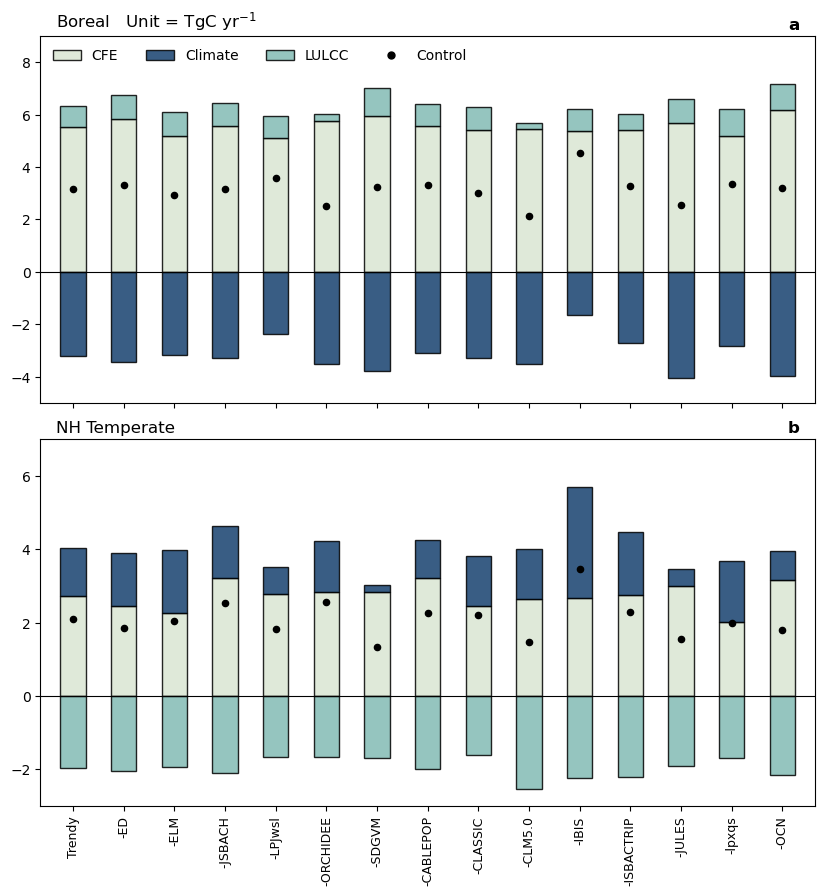

In [8]:
# 创建图形和子图
fig = plt.figure(figsize=(10, 10))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.1)
axs = [fig.add_subplot(gs[i]) for i in range(2)]

# 定义颜色和标签
colors = ['#dae6d3', '#16416e', '#83bbb4']
x = np.arange(len(loo_scenario_names))
labels = [f'All {len(loo_models)}'] + [f'-{name}' for name in loo_models]
labels[0] = 'Trendy'

# 绘制每个区域的柱状图
for n_r, ax in enumerate(axs):
    region = loo_regions[n_r]
    means = np.stack([loo_ensemble_dict[name]['mean_diff'][n_r] for name in loo_scenario_names]) * 1000.0
    positive, negative = np.zeros(len(x)), np.zeros(len(x))
    
    # 绘制每个实验的柱状图
    for n_e, color in enumerate(colors, start=1):
        values = means[:, n_e]
        ax.bar(
            x, values, bottom=np.where(values >= 0, positive, negative), width=0.5,
            color=color, edgecolor='black', linewidth=1, alpha=0.85
        )
        positive += np.maximum(values, 0)
        negative += np.minimum(values, 0)
    
    # 添加散点、水平线和标题
    ax.scatter(x, means[:, 0], color='black', s=20, zorder=5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.tick_params(axis='y', labelsize=10)
    ax.set_xlim(-0.65, len(x) - 0.35)

# 设置 x 轴标签和刻度
axs[-1].set_xticks(x)
axs[-1].set_xticklabels(labels, rotation=90, ha='center', fontsize=9)

# 添加图例
handles = [mpatches.Patch(facecolor=c, edgecolor='black', alpha=0.85) for c in colors]
handles += [Line2D([0], [0], color='black', marker='o', linestyle='none', markersize=5)]
axs[0].legend(
    handles, ['CFE', 'Climate', 'LULCC', 'Control'], loc='upper left',
    ncols=4, frameon=False, fontsize=10
)
letters = ['a', 'b']
titles = ['Boreal   Unit = TgC yr$^{-1}$', 'NH Temperate']
for i in range(2):
    ax = axs[i]
    ax.set_xticks(x_data)
    if i == 0:
        ax.set_xticklabels([])
    ax.text(0.98, 1.01, letters[i], transform=ax.transAxes, ha='right', va='bottom', 
            fontsize=12, fontweight='bold')
    ax.text(0.02, 1.01, titles[i], transform=ax.transAxes, ha='left', va='bottom', 
            fontsize=12)
axs[0].set_ylim(-5, 9)
axs[1].set_ylim(-3, 7)

plt.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/R1/fig/R8-leave-one-out.png', 
            dpi=400, bbox_inches='tight')